## 0. Setup

In [ ]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, log_loss, ConfusionMatrixDisplay)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)   # always print floats with 4 decimals

SEED = 42
np.random.seed(SEED)

# Files uploaded to /content in Google Colab
DATA_PATH  = "/content/Final_Dataset_AIBD.csv"
GENES_PATH = "/content/median_significant_genes.json"

TEST_SIZE  = 0.10   # 10 % test
VAL_SIZE   = 0.10   # 10 % validation  (-> 80 % train)
VAR_TARGET = 0.80   # keep the smallest number of PCs explaining >= 80 % of the variance
N_TOP      = 25     # number of BIC-ranked genes used for SVM and Random Forest

## 1. Load the data

In [ ]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df = df.drop(columns=["Unnamed: 0.1"]).rename(columns={"Unnamed: 0": "Sample"})

# COVID status is encoded in the sample ID: C* = COVID-positive, NC* = COVID-negative
df["COVID"] = df["Sample"].str.match(r"^C\d+$").astype(int)
df["ICU_flag"] = df["ICU"].map({"yes": 1, "no": 0})   # only defined for COVID-positive samples

print("Shape:", df.shape)
print("\nCOVID status:\n", df["COVID"].map({1: "COVID+", 0: "COVID-"}).value_counts().to_string())
print("\nICU among COVID+:\n", df.loc[df.COVID == 1, "ICU"].value_counts().to_string())

Shape: (185, 17727)

COVID status:
 COVID
COVID+    100
COVID-     85

ICU among COVID+:
 ICU
no     50
yes    50


## 2. Extract the selected genes from the JSON

In [ ]:
with open(GENES_PATH) as f:
    gene_json = json.load(f)

for k, v in gene_json.items():
    print(f"{k:12s}: {len(v)} genes")

# union of both lists, order preserved, duplicates removed
selected = list(dict.fromkeys(gene_json["elevation"] + gene_json["supression"]))
present  = [g for g in selected if g in df.columns]
missing  = [g for g in selected if g not in df.columns]

print(f"\nUnique selected genes : {len(selected)}")
print(f"Found in dataset      : {len(present)}")
print(f"Missing from dataset  : {len(missing)}")

tpm = df[present].astype(float)
print("\nSelected-gene TPM matrix:", tpm.shape)

elevation   : 9005 genes
supression  : 3715 genes

Unique selected genes : 12720
Found in dataset      : 12720
Missing from dataset  : 0

Selected-gene TPM matrix: (185, 12720)


In [ ]:
neg = (tpm < 0).sum(axis=1)

log_tpm = np.log2(tpm.clip(lower=0) + 1)

Samples with negative TPM values: 59 (NC27 ... NC85)
Negative entries: 13003, min value = -385.87


## 3. Helper functions (identical for Part A and Part B)

In [ ]:
def split_data(X, y):
    # Stratified 70 / 15 / 15 train / validation / test split.
    X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                              stratify=y_tv, random_state=SEED)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


def scale(X_tr, X_va, X_te):
    # Drop genes with zero variance in TRAIN, then z-score with TRAIN mean / sd only (no leakage).
    keep = X_tr.columns[X_tr.var() > 0]
    sc = StandardScaler().fit(X_tr[keep])
    f = lambda X: pd.DataFrame(sc.transform(X[keep]), index=X.index, columns=keep)
    return f(X_tr), f(X_va), f(X_te)


def plot_pca(pca, P_tr, y_tr, k, labels, title):
    evr = pca.explained_variance_ratio_
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    ax[0].bar(range(1, 21), evr[:20] * 100)
    ax[0].set(title="Scree plot (first 20 PCs)", xlabel="PC", ylabel="% variance explained")
    ax[1].plot(range(1, len(evr) + 1), np.cumsum(evr) * 100, marker=".")
    ax[1].axhline(VAR_TARGET * 100, ls="--", c="grey"); ax[1].axvline(k, ls="--", c="red")
    ax[1].set(title=f"Cumulative variance ({k} PCs = {np.cumsum(evr)[k-1]*100:.1f}%)",
              xlabel="Number of PCs", ylabel="Cumulative %")
    for cls, name in labels.items():
        m = y_tr == cls
        ax[2].scatter(P_tr[m, 0], P_tr[m, 1], label=name, alpha=.75, edgecolor="k", lw=.3)
    ax[2].set(title="Training samples on PC1 vs PC2",
              xlabel=f"PC1 ({evr[0]*100:.1f}%)", ylabel=f"PC2 ({evr[1]*100:.1f}%)")
    ax[2].legend()
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()


def top_loadings(pca, genes, pcs, n=10):
    out = {}
    for i in pcs:
        s = pd.Series(pca.components_[i], index=genes)
        top = s.abs().sort_values(ascending=False).index[:n]
        out[f"PC{i+1}"] = [f"{g} ({s[g]:+.3f})" for g in top]
    return pd.DataFrame(out)


def bic_logistic(X, y):
    # Lecture formula (linear regression):  BIC_p = SSE_p / sigma^2 + log(n) * p
    # Logistic regression analogue:         BIC_p = -2 log L + log(n) * p
    # p = intercept + number of genes. A very weak L2 penalty (C = 1e4) keeps the fit numerically
    # stable when the classes are (near-)perfectly separable; it is effectively unpenalised.
    n = len(y)
    if X.shape[1] == 0:
        prob = np.full(n, y.mean())
    else:
        prob = LogisticRegression(C=1e4, max_iter=5000).fit(X, y).predict_proba(X)[:, 1]
    log_lik = -log_loss(y, prob, normalize=False)
    return -2 * log_lik + np.log(n) * (X.shape[1] + 1)


def forward_step(X, y, selected, candidates):
    # One forward step: try adding each remaining candidate, return the one with the lowest BIC.
    remaining = [g for g in candidates if g not in selected]
    scores = pd.Series({g: bic_logistic(X[selected + [g]], y) for g in remaining})
    return scores.idxmin(), scores.min()


def forward_selection_bic(X, y, candidates, max_steps=20):
    # Lecture procedure with BIC: start with no IVs -> add the gene giving the lowest BIC -> repeat
    # -> stop when the best new BIC is not lower than the current BIC and keep the previous model.
    selected = []
    current = bic_logistic(X[[]], y)
    history = [{"step": 0, "added_gene": "(intercept only)", "BIC": current, "n_genes": 0}]
    for step in range(1, max_steps + 1):
        gene, bic = forward_step(X, y, selected, candidates)
        if bic >= current:
            print(f"Step {step}: best candidate {gene} gives BIC {bic:.2f} >= current {current:.2f} -> STOP")
            break
        selected.append(gene); current = bic
        history.append({"step": step, "added_gene": gene, "BIC": bic, "n_genes": len(selected)})
        print(f"Step {step}: add {gene:12s} BIC = {bic:.2f}")
    return selected, pd.DataFrame(history)


def bic_ranking(X, y, candidates, start, n_total):
    # Continue the same forward steps from the BIC-selected genes, without the stop rule,
    # until n_total genes are ranked. The first genes are exactly the BIC-selected ones.
    ranked = list(start)
    rows = [{"rank": i + 1, "gene": g, "BIC after adding": bic_logistic(X[list(start[:i + 1])], y), "in BIC model": True}
            for i, g in enumerate(start)]
    while len(ranked) < n_total:
        gene, bic = forward_step(X, y, ranked, candidates)
        ranked.append(gene)
        rows.append({"rank": len(ranked), "gene": gene, "BIC after adding": bic, "in BIC model": False})
    return ranked, pd.DataFrame(rows).set_index("rank")


def tune_on_validation(make_model, grid, X_tr, y_tr, X_va, y_va):
    # Fit one model per setting on TRAIN; pick the best on VALIDATION (F1, then accuracy).
    rows = []
    for params in grid:
        pred = make_model(**params).fit(X_tr, y_tr).predict(X_va)
        rows.append({**params, "val_accuracy": accuracy_score(y_va, pred),
                     "val_F1": f1_score(y_va, pred, zero_division=0)})
    res = pd.DataFrame(rows)
    best = res.sort_values(["val_F1", "val_accuracy"], ascending=False, kind="stable").iloc[0]
    best_params = {}
    for k in grid[0]:
        v = best[k]
        if v is None or (isinstance(v, float) and np.isnan(v)):
            best_params[k] = None
        elif isinstance(v, (float, np.floating)):
            best_params[k] = int(v) if (k != "C" and float(v).is_integer()) else float(v)
        else:
            best_params[k] = v
    return best_params, res


def metrics(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall (Sensitivity)": recall_score(y, pred, zero_division=0),
            "Specificity": tn / (tn + fp),
            "F1 score": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, prob),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}


def evaluate(name, model, X, y, labels, title):
    # Prints the metrics table and plots the ROC curve + confusion matrix for one model on the TEST set.
    m = metrics(model, X, y)
    table = pd.DataFrame([m], index=[name]).round(4)
    for c in ("TN", "FP", "FN", "TP"):
        table[c] = table[c].astype(int)
    print(f"{title} - {name} - TEST set (n = {len(y)}, positive class = {labels[1]})\n")
    print(table.to_string())

    prob = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, prob)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
    ax[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {m['ROC-AUC']:.3f})")
    ax[0].plot([0, 1], [0, 1], ls="--", c="grey", label="Chance (AUC = 0.5)")
    ax[0].set(title="ROC curve", xlabel="False positive rate (1 - specificity)",
              ylabel="True positive rate (sensitivity)")
    ax[0].legend(loc="lower right"); ax[0].grid(alpha=.3)
    ConfusionMatrixDisplay(confusion_matrix(y, model.predict(X), labels=[0, 1]),
                           display_labels=[labels[0], labels[1]]).plot(ax=ax[1], cmap="Blues", colorbar=False)
    ax[1].set_title("Confusion matrix")
    fig.suptitle(f"{title} - {name} (TEST set)", fontsize=13); plt.tight_layout(); plt.show()
    return m


LR_GRID  = [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10, 100]]
SVM_GRID = [{"kernel": k, "C": c} for k in ["linear", "rbf"] for c in [0.01, 0.1, 1, 10, 100]]
RF_GRID  = [{"max_depth": d, "min_samples_leaf": l} for d in [None, 3, 5] for l in [1, 3, 5]]

make_lr  = lambda **p: LogisticRegression(max_iter=5000, random_state=SEED, **p)
make_svm = lambda **p: SVC(probability=True, random_state=SEED, **p)
make_rf  = lambda **p: RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, **p)

---
# Part A: COVID-positive vs COVID-negative

All 185 samples are used. Positive class = **COVID+**.

## A.1 Labels and train / validation / test split (70 / 15 / 15)

In [ ]:
mask_A = df["COVID"].notna()
X_A = log_tpm.loc[mask_A]
y_A = df.loc[mask_A, "COVID"].astype(int).values
LABELS_A = {0: 'COVID-', 1: 'COVID+'}
TITLE_A = "COVID-positive vs COVID-negative"

Xtr_A, Xva_A, Xte_A, ytr_A, yva_A, yte_A = split_data(X_A, y_A)
pd.DataFrame({s: {LABELS_A[c]: int((yy == c).sum()) for c in (0, 1)} | {"Total": len(yy)}
              for s, yy in [("Train", ytr_A), ("Validation", yva_A), ("Test", yte_A)]})

,Train,Validation,Test
COVID-,67,9,9
COVID+,80,10,10
Total,147,19,19


## A.2 PCA on the selected genes



Genes used for PCA (non-zero variance in train): 12720
PCs needed for >= 80% variance: 42
Variance explained by PC1-PC5 (%): [34.07 13.87  3.95  2.96  2.46]


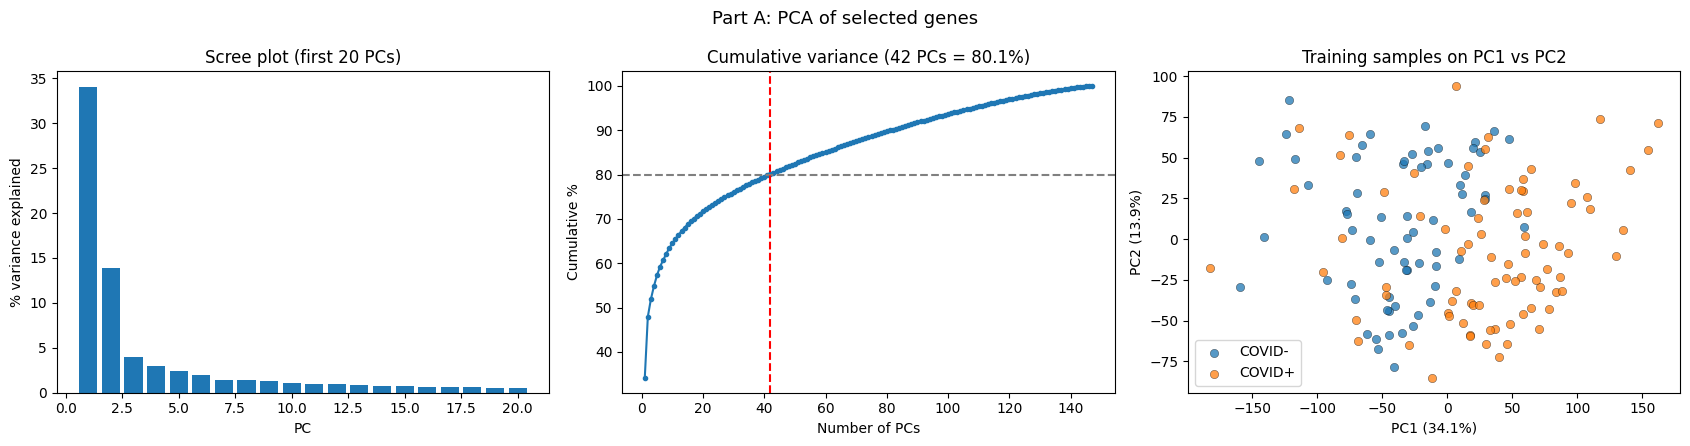

In [ ]:
Ztr_A, Zva_A, Zte_A = scale(Xtr_A, Xva_A, Xte_A)
genes_A = Ztr_A.columns
print("Genes used for PCA (non-zero variance in train):", len(genes_A))

pca_A = PCA(random_state=SEED).fit(Ztr_A)
k_A = int(np.searchsorted(np.cumsum(pca_A.explained_variance_ratio_), VAR_TARGET) + 1)
print(f"PCs needed for >= {VAR_TARGET:.0%} variance: {k_A}")
print("Variance explained by PC1-PC5 (%):", np.round(pca_A.explained_variance_ratio_[:5] * 100, 2))

pc_cols_A = [f"PC{i+1}" for i in range(k_A)]
Ptr_A = pca_A.transform(Ztr_A)[:, :k_A]
Pva_A = pca_A.transform(Zva_A)[:, :k_A]

plot_pca(pca_A, Ptr_A, ytr_A, k_A, LABELS_A, f"Part A: PCA of selected genes")

Top-loading genes on the first three principal components:

In [ ]:
top_loadings(pca_A, genes_A, pcs=[0, 1, 2], n=10)

,PC1,PC2,PC3
0,U2SURP (+0.015),DUS1L (+0.023),CYTH4 (+0.034)
1,TRPM7 (+0.015),PIH1D1 (+0.022),PTTG1 (-0.033)
2,USP24 (+0.015),ABHD14B (+0.022),SLC12A9 (+0.033)
3,RPS6KB1 (+0.015),ATP6V0E2 (+0.022),CENPA (-0.032)
4,SMARCA5 (+0.015),POLRMT (+0.022),ARAP1 (+0.032)
5,ANKIB1 (+0.015),GFER (+0.022),CDKN3 (-0.032)
6,PPP2R5E (+0.015),SIGIRR (+0.022),CIC (+0.032)
7,ZSCAN29 (+0.015),RPL18 (+0.022),CSK (+0.032)
8,OTUD4 (+0.015),EEFSEC (+0.022),BIRC5 (-0.032)
9,SOCS4 (+0.015),ZNF428 (+0.022),CCNB2 (-0.032)


## A.3 Logistic regression on the principal components



In [ ]:
best_pc_A, grid_pc_A = tune_on_validation(make_lr, LR_GRID, Ptr_A, ytr_A, Pva_A, yva_A)
print(grid_pc_A.round(4).to_string(index=False))
lr_pc_A = make_lr(**best_pc_A).fit(Ptr_A, ytr_A)
print("\nChosen:", best_pc_A)
print(f"Train accuracy = {accuracy_score(ytr_A, lr_pc_A.predict(Ptr_A)):.3f} | "
      f"Validation accuracy = {accuracy_score(yva_A, lr_pc_A.predict(Pva_A)):.3f}")

# PC scores have different spreads -> rank PCs by |coefficient| x SD
pc_imp_A = pd.Series(np.abs(lr_pc_A.coef_[0]) * Ptr_A.std(axis=0), index=pc_cols_A).sort_values(ascending=False)
print("\nMost predictive PCs (|coef| x SD):")
print(pc_imp_A.head(10).round(4).to_string())

       C  val_accuracy  val_F1
  0.0010        0.9474  0.9474
  0.0100        0.9474  0.9474
  0.1000        0.9474  0.9474
  1.0000        0.9474  0.9474
 10.0000        0.9474  0.9474
100.0000        0.9474  0.9474

Chosen: {'C': 0.001}
Train accuracy = 0.993 | Validation accuracy = 0.947

Most predictive PCs (|coef| x SD):
PC1    2.2426
PC3    2.0391
PC4    1.0421
PC2    0.6278
PC13   0.4360
PC9    0.3201
PC6    0.2958
PC14   0.2816
PC20   0.2379
PC18   0.1860


## A.4 Forward selection using BIC




Candidate pool from ['PC1', 'PC3', 'PC4', 'PC2', 'PC13']: 150 genes

Step 1: add CCNB1        BIC = 83.85
Step 2: add HAGH         BIC = 71.71
Step 3: add CARD19       BIC = 65.59
Step 4: add REC8         BIC = 57.48
Step 5: add SOCS4        BIC = 55.39
Step 6: add SLC6A8       BIC = 51.44
Step 7: add CA2          BIC = 41.42
Step 8: best candidate BLVRB gives BIC 45.18 >= current 41.42 -> STOP

FINAL BIC GENE LIST: ['CCNB1', 'HAGH', 'CARD19', 'REC8', 'SOCS4', 'SLC6A8', 'CA2']

 step       added_gene      BIC  n_genes
    0 (intercept only) 207.6200        0
    1            CCNB1  83.8500        1
    2             HAGH  71.7100        2
    3           CARD19  65.5900        3
    4             REC8  57.4800        4
    5            SOCS4  55.3900        5
    6           SLC6A8  51.4400        6
    7              CA2  41.4200        7


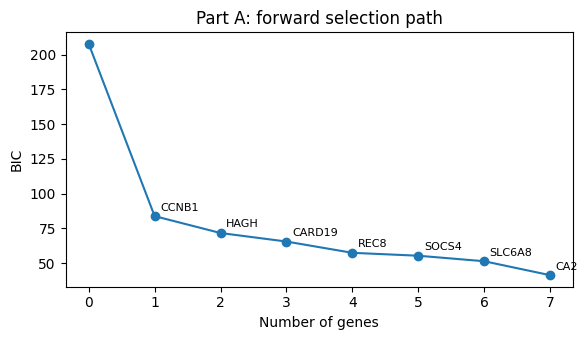

In [ ]:
TOP_PCS, GENES_PER_PC = 5, 30
cand_A = []
for pc in pc_imp_A.index[:TOP_PCS]:
    load = pd.Series(pca_A.components_[int(pc[2:]) - 1], index=genes_A)
    cand_A += list(load.abs().sort_values(ascending=False).index[:GENES_PER_PC])
cand_A = list(dict.fromkeys(cand_A))
print(f"Candidate pool from {list(pc_imp_A.index[:TOP_PCS])}: {len(cand_A)} genes\n")

final_genes_A, bic_hist_A = forward_selection_bic(Ztr_A, ytr_A, cand_A)
print("\nFINAL BIC GENE LIST:", final_genes_A)
print()
print(bic_hist_A.round(2).to_string(index=False))

plt.figure(figsize=(6, 3.5))
plt.plot(bic_hist_A["n_genes"], bic_hist_A["BIC"], marker="o")
for _, r in bic_hist_A.iloc[1:].iterrows():
    plt.annotate(r["added_gene"], (r["n_genes"], r["BIC"]), textcoords="offset points", xytext=(4, 4), fontsize=8)
plt.xlabel("Number of genes"); plt.ylabel("BIC"); plt.title("Part A: forward selection path")
plt.tight_layout(); plt.show()

## A.5 Final logistic regression on the BIC-selected genes

In [ ]:
Ltr_A, Lva_A, Lte_A = Ztr_A[final_genes_A], Zva_A[final_genes_A], Zte_A[final_genes_A]

best_lr_A, grid_lr_A = tune_on_validation(make_lr, LR_GRID, Ltr_A, ytr_A, Lva_A, yva_A)
print(grid_lr_A.round(4).to_string(index=False))
lr_A = make_lr(**best_lr_A).fit(Ltr_A, ytr_A)
print("\nChosen:", best_lr_A)
print("\nCoefficients (per 1 SD of log2 TPM):")
print(pd.Series(lr_A.coef_[0], index=final_genes_A, name="coefficient").round(4).to_string())

       C  val_accuracy  val_F1
  0.0010        0.5789  0.7143
  0.0100        0.9474  0.9474
  0.1000        0.9474  0.9474
  1.0000        0.9474  0.9474
 10.0000        0.9474  0.9474
100.0000        0.9474  0.9474

Chosen: {'C': 0.01}

Coefficients (per 1 SD of log2 TPM):
CCNB1     0.3491
HAGH     -0.2072
CARD19   -0.0908
REC8      0.1975
SOCS4     0.1908
SLC6A8    0.0230
CA2       0.1266


### A.5.1 Evaluation — Logistic Regression

COVID-positive vs COVID-negative - Logistic Regression - TEST set (n = 19, positive class = COVID+)

                     Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression    0.8947     1.0000                0.8000       1.0000    0.8889   0.9778   9   0   2   8


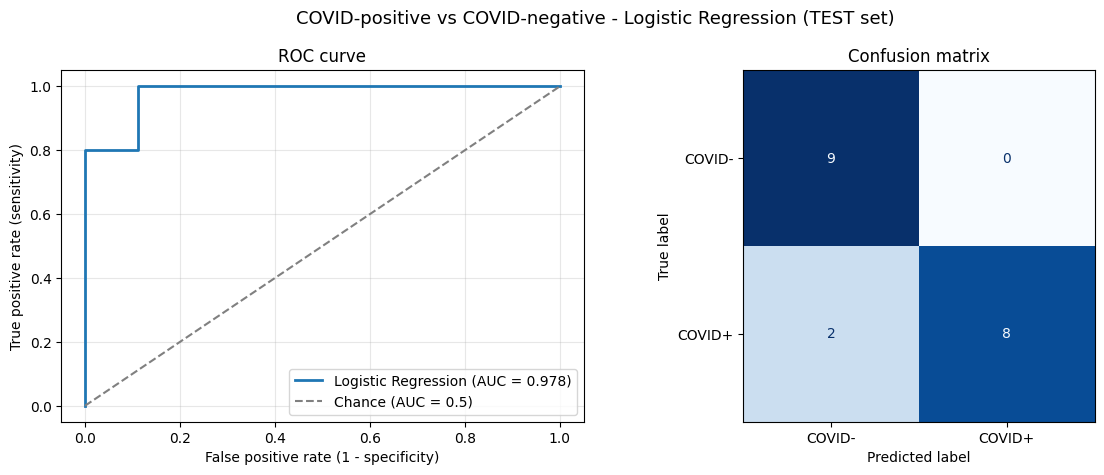

In [ ]:
m_lr_A = evaluate("Logistic Regression", lr_A, Lte_A, yte_A, LABELS_A, TITLE_A)

## A.6 Top 25 genes by BIC ranking (for SVM and Random Forest)



In [ ]:
top_genes_A, top_tbl_A = bic_ranking(Ztr_A, ytr_A, cand_A, final_genes_A, N_TOP)
print(top_tbl_A.round(2).to_string())

Ttr_A, Tva_A, Tte_A = Ztr_A[top_genes_A], Zva_A[top_genes_A], Zte_A[top_genes_A]

        gene  BIC after adding  in BIC model
rank                                        
1      CCNB1           83.8500          True
2       HAGH           71.7100          True
3     CARD19           65.5900          True
4       REC8           57.4800          True
5      SOCS4           55.3900          True
6     SLC6A8           51.4400          True
7        CA2           41.4200          True
8      BLVRB           45.1800         False
9       OIP5           50.0300         False
10      GOPC           54.9700         False
11    BCL2L1           59.9600         False
12      GPX1           64.9400         False
13     RPS16           69.9200         False
14    POLRMT           74.9000         False
15      DBN1           79.8900         False
16     PTPN5           84.8700         False
17     RPL19           89.8600         False
18    RABEP1           94.8400         False
19      YDJC           99.8400         False
20      FGD3          104.8300         False
21     PCL

## A.7 SVM on the top 25 genes

In [ ]:
best_svm_A, grid_svm_A = tune_on_validation(make_svm, SVM_GRID, Ttr_A, ytr_A, Tva_A, yva_A)
print(grid_svm_A.round(4).to_string(index=False))
svm_A = make_svm(**best_svm_A).fit(Ttr_A, ytr_A)
print("\nChosen on validation:", best_svm_A)

kernel        C  val_accuracy  val_F1
linear   0.0100        0.9474  0.9474
linear   0.1000        0.9474  0.9474
linear   1.0000        0.9474  0.9474
linear  10.0000        0.9474  0.9474
linear 100.0000        0.9474  0.9474
   rbf   0.0100        0.5263  0.6897
   rbf   0.1000        0.9474  0.9474
   rbf   1.0000        0.9474  0.9474
   rbf  10.0000        0.9474  0.9474
   rbf 100.0000        0.9474  0.9474

Chosen on validation: {'kernel': 'linear', 'C': 0.01}


### A.7.1 Evaluation — SVM

COVID-positive vs COVID-negative - SVM - TEST set (n = 19, positive class = COVID+)

     Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
SVM    0.8421     1.0000                0.7000       1.0000    0.8235   1.0000   9   0   3   7


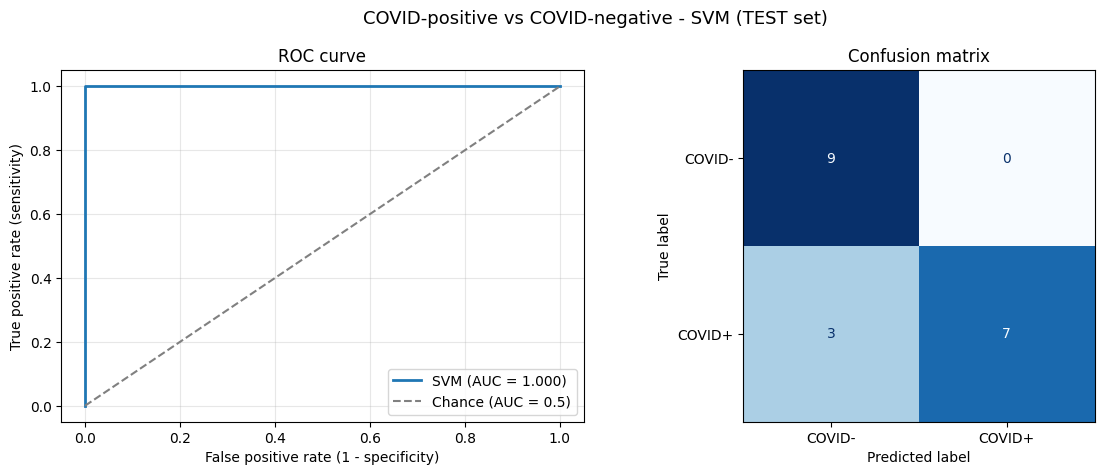

In [ ]:
m_svm_A = evaluate("SVM", svm_A, Tte_A, yte_A, LABELS_A, TITLE_A)

## A.8 Random Forest on the top 25 genes

In [ ]:
best_rf_A, grid_rf_A = tune_on_validation(make_rf, RF_GRID, Ttr_A, ytr_A, Tva_A, yva_A)
print(grid_rf_A.round(4).to_string(index=False))
rf_A = make_rf(**best_rf_A).fit(Ttr_A, ytr_A)
print("\nChosen on validation:", best_rf_A)
print("\nFeature importance:")
print(pd.Series(rf_A.feature_importances_, index=top_genes_A).sort_values(ascending=False).round(4).to_string())

 max_depth  min_samples_leaf  val_accuracy  val_F1
       NaN                 1        0.9474  0.9474
       NaN                 3        0.9474  0.9474
       NaN                 5        0.8947  0.8889
    3.0000                 1        0.9474  0.9474
    3.0000                 3        0.8947  0.8889
    3.0000                 5        0.8947  0.8889
    5.0000                 1        0.9474  0.9474
    5.0000                 3        0.9474  0.9474
    5.0000                 5        0.8947  0.8889

Chosen on validation: {'max_depth': None, 'min_samples_leaf': 1}

Feature importance:
CCNB1    0.2020
PCLAF    0.1973
OIP5     0.1266
SOCS4    0.0701
HAGH     0.0573
REC8     0.0360
NNT      0.0358
CA2      0.0357
BLVRB    0.0277
GPX1     0.0256
CARD19   0.0202
BCL2L1   0.0189
FGD3     0.0173
RABEP1   0.0172
PTPN5    0.0137
SLC6A8   0.0137
POLRMT   0.0131
GOPC     0.0109
YDJC     0.0101
EPOR     0.0092
OR2W3    0.0088
DBN1     0.0087
GIPC1    0.0087
RPL19    0.0079
RPS16    0.0075


### A.8.1 Evaluation — Random Forest

COVID-positive vs COVID-negative - Random Forest - TEST set (n = 19, positive class = COVID+)

               Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Random Forest    0.9474     1.0000                0.9000       1.0000    0.9474   1.0000   9   0   1   9


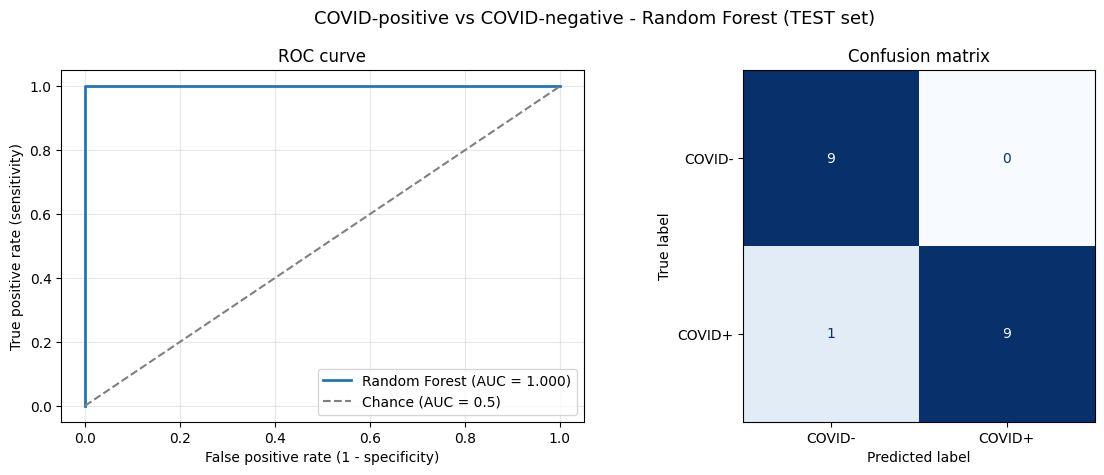

In [ ]:
m_rf_A = evaluate("Random Forest", rf_A, Tte_A, yte_A, LABELS_A, TITLE_A)

## A.9 Model comparison — COVID-positive vs COVID-negative (test set)

In [ ]:
results_A = pd.DataFrame({"Logistic Regression (BIC genes)": m_lr_A,
                              "SVM (top 25 genes)": m_svm_A,
                              "Random Forest (top 25 genes)": m_rf_A}).T
results_A[["TN", "FP", "FN", "TP"]] = results_A[["TN", "FP", "FN", "TP"]].astype(int)
print(f"{TITLE_A} - TEST set (n = {len(yte_A)}, positive class = {LABELS_A[1]})\n")
print(results_A.round(4).to_string())

COVID-positive vs COVID-negative - TEST set (n = 19, positive class = COVID+)

                                 Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression (BIC genes)    0.8947     1.0000                0.8000       1.0000    0.8889   0.9778   9   0   2   8
SVM (top 25 genes)                 0.8421     1.0000                0.7000       1.0000    0.8235   1.0000   9   0   3   7
Random Forest (top 25 genes)       0.9474     1.0000                0.9000       1.0000    0.9474   1.0000   9   0   1   9


---
# Part B: ICU vs non-ICU (COVID-positive only)



## 1. Labels and train / validation / test split (70 / 15 / 15)

In [ ]:
mask_B = df["COVID"] == 1
X_B = log_tpm.loc[mask_B]
y_B = df.loc[mask_B, "ICU_flag"].astype(int).values
LABELS_B = {0: 'non-ICU', 1: 'ICU'}
TITLE_B = "ICU vs non-ICU (COVID-positive only)"

Xtr_B, Xva_B, Xte_B, ytr_B, yva_B, yte_B = split_data(X_B, y_B)
pd.DataFrame({s: {LABELS_B[c]: int((yy == c).sum()) for c in (0, 1)} | {"Total": len(yy)}
              for s, yy in [("Train", ytr_B), ("Validation", yva_B), ("Test", yte_B)]})

,Train,Validation,Test
non-ICU,40,5,5
ICU,40,5,5
Total,80,10,10


## 2. PCA on the selected genes



Genes used for PCA (non-zero variance in train): 12594
PCs needed for >= 80% variance: 25
Variance explained by PC1-PC5 (%): [36.3  14.43  4.31  3.4   2.52]


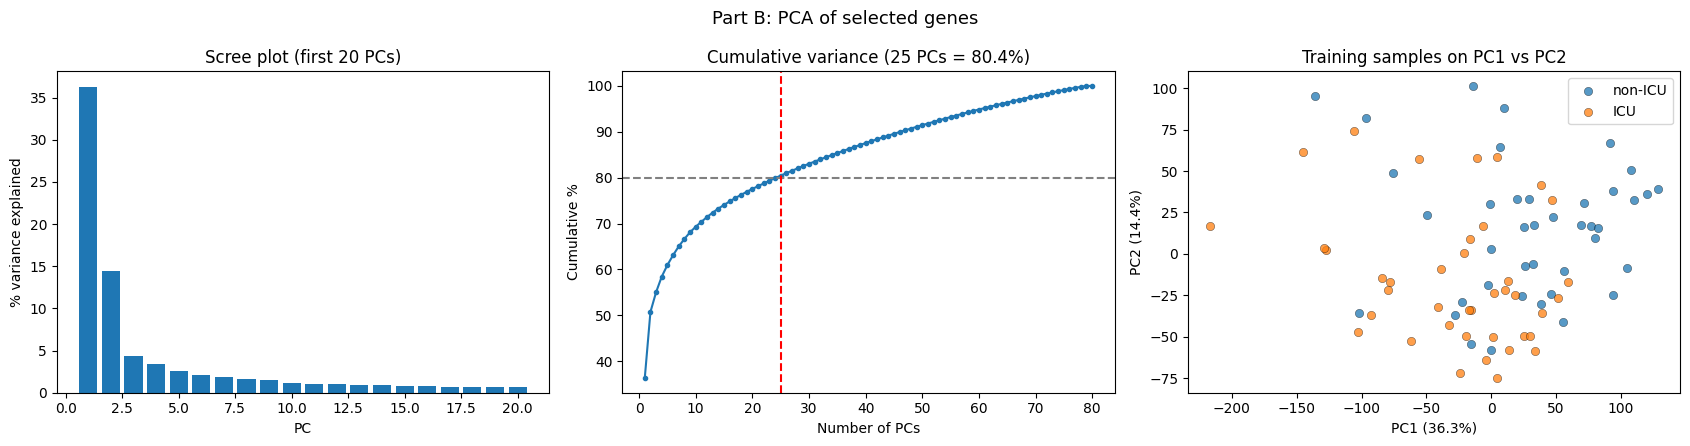

In [ ]:
Ztr_B, Zva_B, Zte_B = scale(Xtr_B, Xva_B, Xte_B)
genes_B = Ztr_B.columns
print("Genes used for PCA (non-zero variance in train):", len(genes_B))

pca_B = PCA(random_state=SEED).fit(Ztr_B)
k_B = int(np.searchsorted(np.cumsum(pca_B.explained_variance_ratio_), VAR_TARGET) + 1)
print(f"PCs needed for >= {VAR_TARGET:.0%} variance: {k_B}")
print("Variance explained by PC1-PC5 (%):", np.round(pca_B.explained_variance_ratio_[:5] * 100, 2))

pc_cols_B = [f"PC{i+1}" for i in range(k_B)]
Ptr_B = pca_B.transform(Ztr_B)[:, :k_B]
Pva_B = pca_B.transform(Zva_B)[:, :k_B]

plot_pca(pca_B, Ptr_B, ytr_B, k_B, LABELS_B, f"Part B: PCA of selected genes")

Top-loading genes on the first three principal components:

In [ ]:
top_loadings(pca_B, genes_B, pcs=[0, 1, 2], n=10)

,PC1,PC2,PC3
0,NUP160 (+0.014),RPS15 (+0.023),WAS (+0.039)
1,SEC23IP (+0.014),RPS19 (+0.022),FGD3 (+0.039)
2,NIP7 (+0.014),RPL36 (+0.022),STX10 (+0.036)
3,TGS1 (+0.014),PTGES2 (+0.022),DTX2 (+0.036)
4,BAZ1B (+0.014),RPL18A (+0.022),MOB3A (+0.036)
5,EIF3A (+0.014),RPL35 (+0.022),TSC22D4 (+0.036)
6,CAPRIN1 (+0.014),MRPL38 (+0.022),ARAP1 (+0.035)
7,U2SURP (+0.014),DGCR6L (+0.022),ADAM8 (+0.035)
8,TCF12 (+0.014),HRAS (+0.022),TFEB (+0.035)
9,DHX15 (+0.014),LSM7 (+0.022),APOBR (+0.035)


## 3. Logistic regression on the principal components



In [ ]:
best_pc_B, grid_pc_B = tune_on_validation(make_lr, LR_GRID, Ptr_B, ytr_B, Pva_B, yva_B)
print(grid_pc_B.round(4).to_string(index=False))
lr_pc_B = make_lr(**best_pc_B).fit(Ptr_B, ytr_B)
print("\nChosen:", best_pc_B)
print(f"Train accuracy = {accuracy_score(ytr_B, lr_pc_B.predict(Ptr_B)):.3f} | "
      f"Validation accuracy = {accuracy_score(yva_B, lr_pc_B.predict(Pva_B)):.3f}")

# PC scores have different spreads -> rank PCs by |coefficient| x SD
pc_imp_B = pd.Series(np.abs(lr_pc_B.coef_[0]) * Ptr_B.std(axis=0), index=pc_cols_B).sort_values(ascending=False)
print("\nMost predictive PCs (|coef| x SD):")
print(pc_imp_B.head(10).round(4).to_string())

       C  val_accuracy  val_F1
  0.0010        0.9000  0.9091
  0.0100        0.9000  0.9091
  0.1000        0.9000  0.9091
  1.0000        0.9000  0.9091
 10.0000        0.9000  0.9091
100.0000        0.9000  0.9091

Chosen: {'C': 0.001}
Train accuracy = 0.900 | Validation accuracy = 0.900

Most predictive PCs (|coef| x SD):
PC1    1.4635
PC4    1.1309
PC2    1.0922
PC3    0.4856
PC14   0.4242
PC12   0.3467
PC19   0.2759
PC10   0.2258
PC11   0.2125
PC21   0.1749


## 4. Forward selection using BIC



Candidate pool from ['PC1', 'PC4', 'PC2', 'PC3', 'PC14']: 150 genes

Step 1: add HERC6        BIC = 96.30
Step 2: add DUS1L        BIC = 88.41
Step 3: add HROB         BIC = 79.63
Step 4: add GSC2         BIC = 75.90
Step 5: add UBE2C        BIC = 73.87
Step 6: add DIS3         BIC = 69.94
Step 7: add CATSPERE     BIC = 68.27
Step 8: add FBXL6        BIC = 67.10
Step 9: add TRMT61A      BIC = 66.97
Step 10: add DPP7         BIC = 65.30
Step 11: add HESX1        BIC = 53.41
Step 12: best candidate NIP7 gives BIC 57.29 >= current 53.41 -> STOP

FINAL BIC GENE LIST: ['HERC6', 'DUS1L', 'HROB', 'GSC2', 'UBE2C', 'DIS3', 'CATSPERE', 'FBXL6', 'TRMT61A', 'DPP7', 'HESX1']

 step       added_gene      BIC  n_genes
    0 (intercept only) 115.2900        0
    1            HERC6  96.3000        1
    2            DUS1L  88.4100        2
    3             HROB  79.6300        3
    4             GSC2  75.9000        4
    5            UBE2C  73.8700        5
    6             DIS3  69.9400        6


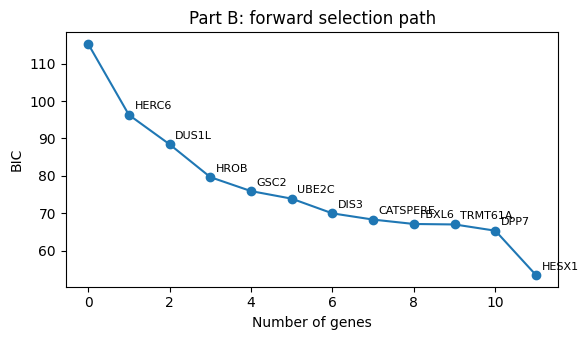

In [ ]:
TOP_PCS, GENES_PER_PC = 5, 30
cand_B = []
for pc in pc_imp_B.index[:TOP_PCS]:
    load = pd.Series(pca_B.components_[int(pc[2:]) - 1], index=genes_B)
    cand_B += list(load.abs().sort_values(ascending=False).index[:GENES_PER_PC])
cand_B = list(dict.fromkeys(cand_B))
print(f"Candidate pool from {list(pc_imp_B.index[:TOP_PCS])}: {len(cand_B)} genes\n")

final_genes_B, bic_hist_B = forward_selection_bic(Ztr_B, ytr_B, cand_B)
print("\nFINAL BIC GENE LIST:", final_genes_B)
print()
print(bic_hist_B.round(2).to_string(index=False))

plt.figure(figsize=(6, 3.5))
plt.plot(bic_hist_B["n_genes"], bic_hist_B["BIC"], marker="o")
for _, r in bic_hist_B.iloc[1:].iterrows():
    plt.annotate(r["added_gene"], (r["n_genes"], r["BIC"]), textcoords="offset points", xytext=(4, 4), fontsize=8)
plt.xlabel("Number of genes"); plt.ylabel("BIC"); plt.title("Part B: forward selection path")
plt.tight_layout(); plt.show()

## B.5 Final logistic regression on the BIC-selected genes

In [ ]:
Ltr_B, Lva_B, Lte_B = Ztr_B[final_genes_B], Zva_B[final_genes_B], Zte_B[final_genes_B]

best_lr_B, grid_lr_B = tune_on_validation(make_lr, LR_GRID, Ltr_B, ytr_B, Lva_B, yva_B)
print(grid_lr_B.round(4).to_string(index=False))
lr_B = make_lr(**best_lr_B).fit(Ltr_B, ytr_B)
print("\nChosen:", best_lr_B)
print("\nCoefficients (per 1 SD of log2 TPM):")
print(pd.Series(lr_B.coef_[0], index=final_genes_B, name="coefficient").round(4).to_string())

       C  val_accuracy  val_F1
  0.0010        0.8000  0.8000
  0.0100        0.8000  0.8000
  0.1000        0.9000  0.8889
  1.0000        0.9000  0.8889
 10.0000        0.9000  0.8889
100.0000        0.9000  0.8889

Chosen: {'C': 0.1}

Coefficients (per 1 SD of log2 TPM):
HERC6      -0.4138
DUS1L      -0.2930
HROB        0.4889
GSC2        0.3634
UBE2C       0.4394
DIS3       -0.5482
CATSPERE    0.2086
FBXL6      -0.2672
TRMT61A    -0.1281
DPP7       -0.2119
HESX1      -0.1548


### B.5.1 Evaluation — Logistic Regression

ICU vs non-ICU (COVID-positive only) - Logistic Regression - TEST set (n = 10, positive class = ICU)

                     Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression    0.9000     1.0000                0.8000       1.0000    0.8889   0.9600   5   0   1   4


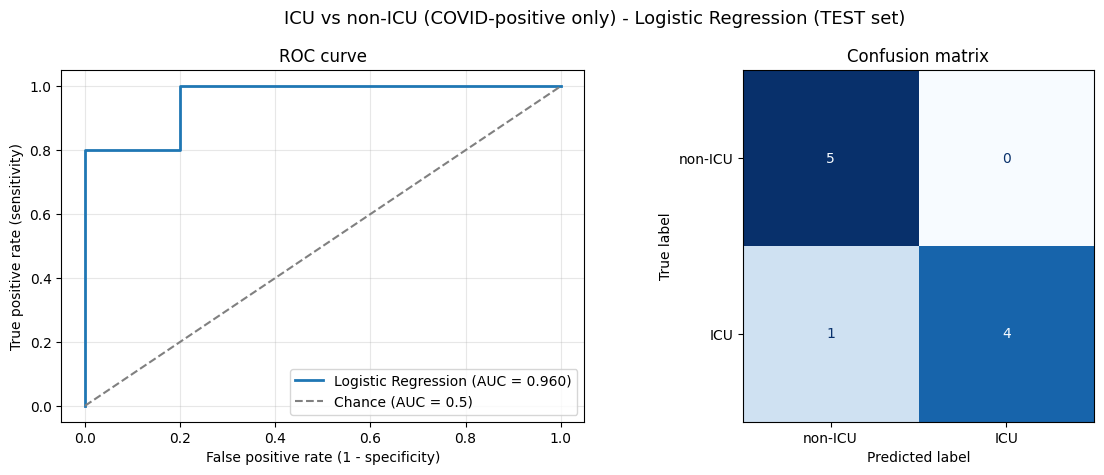

In [ ]:
m_lr_B = evaluate("Logistic Regression", lr_B, Lte_B, yte_B, LABELS_B, TITLE_B)

## 6. Top 25 genes by BIC ranking (for SVM and Random Forest)



In [ ]:
top_genes_B, top_tbl_B = bic_ranking(Ztr_B, ytr_B, cand_B, final_genes_B, N_TOP)
print(top_tbl_B.round(2).to_string())

Ttr_B, Tva_B, Tte_B = Ztr_B[top_genes_B], Zva_B[top_genes_B], Zte_B[top_genes_B]

          gene  BIC after adding  in BIC model
rank                                          
1        HERC6           96.3000          True
2        DUS1L           88.4100          True
3         HROB           79.6300          True
4         GSC2           75.9000          True
5        UBE2C           73.8700          True
6         DIS3           69.9400          True
7     CATSPERE           68.2700          True
8        FBXL6           67.1000          True
9      TRMT61A           66.9700          True
10        DPP7           65.3000          True
11       HESX1           53.4100          True
12        NIP7           57.2900         False
13        NOS1           61.5800         False
14       PLAC8           65.8800         False
15       ADAM8           70.2000         False
16        SPI1           74.5400         False
17     TSC22D4           78.9200         False
18       PTGIS           83.3000         False
19     SUPT16H           87.6800         False
20    ZC3HAV1

## 7. SVM on the top 25 genes

In [ ]:
best_svm_B, grid_svm_B = tune_on_validation(make_svm, SVM_GRID, Ttr_B, ytr_B, Tva_B, yva_B)
print(grid_svm_B.round(4).to_string(index=False))
svm_B = make_svm(**best_svm_B).fit(Ttr_B, ytr_B)
print("\nChosen on validation:", best_svm_B)

kernel        C  val_accuracy  val_F1
linear   0.0100        0.7000  0.7273
linear   0.1000        0.8000  0.8000
linear   1.0000        0.6000  0.6000
linear  10.0000        0.5000  0.4444
linear 100.0000        0.5000  0.4444
   rbf   0.0100        0.9000  0.9091
   rbf   0.1000        0.9000  0.9091
   rbf   1.0000        0.8000  0.8000
   rbf  10.0000        0.8000  0.8000
   rbf 100.0000        0.8000  0.8000

Chosen on validation: {'kernel': 'rbf', 'C': 0.01}


### 8. Evaluation — SVM

ICU vs non-ICU (COVID-positive only) - SVM - TEST set (n = 10, positive class = ICU)

     Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
SVM    0.8000     1.0000                0.6000       1.0000    0.7500   0.0400   5   0   2   3


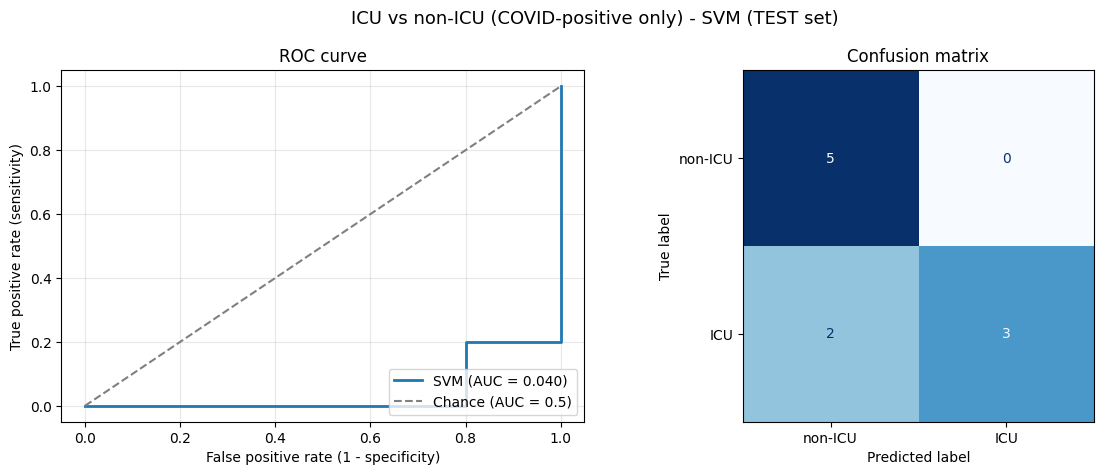

In [ ]:
m_svm_B = evaluate("SVM", svm_B, Tte_B, yte_B, LABELS_B, TITLE_B)

## 9. Random Forest on the top 25 genes

In [ ]:
best_rf_B, grid_rf_B = tune_on_validation(make_rf, RF_GRID, Ttr_B, ytr_B, Tva_B, yva_B)
print(grid_rf_B.round(4).to_string(index=False))
rf_B = make_rf(**best_rf_B).fit(Ttr_B, ytr_B)
print("\nChosen on validation:", best_rf_B)
print("\nFeature importance:")
print(pd.Series(rf_B.feature_importances_, index=top_genes_B).sort_values(ascending=False).round(4).to_string())

 max_depth  min_samples_leaf  val_accuracy  val_F1
       NaN                 1        0.8000  0.8000
       NaN                 3        0.8000  0.8000
       NaN                 5        0.9000  0.9091
    3.0000                 1        0.8000  0.8000
    3.0000                 3        0.8000  0.8000
    3.0000                 5        0.9000  0.9091
    5.0000                 1        0.8000  0.8000
    5.0000                 3        0.8000  0.8000
    5.0000                 5        0.9000  0.9091

Chosen on validation: {'max_depth': None, 'min_samples_leaf': 5}

Feature importance:
HERC6      0.1279
HROB       0.1126
DUS1L      0.0983
NIP7       0.0791
UBE2C      0.0568
EIF3A      0.0527
SUPT16H    0.0487
FBXL6      0.0480
PLAC8      0.0459
DIS3       0.0440
HESX1      0.0425
TRMT61A    0.0403
ZC3HAV1L   0.0386
ETV7       0.0378
DPP7       0.0279
VWF        0.0193
CATSPERE   0.0155
PTGIS      0.0151
ADAM8      0.0148
TSC22D4    0.0122
PDLIM7     0.0091
SPI1       0.0083
PROX1  

### 10. Evaluation — Random Forest

ICU vs non-ICU (COVID-positive only) - Random Forest - TEST set (n = 10, positive class = ICU)

               Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Random Forest    0.6000     0.6000                0.6000       0.6000    0.6000   0.7600   3   2   2   3


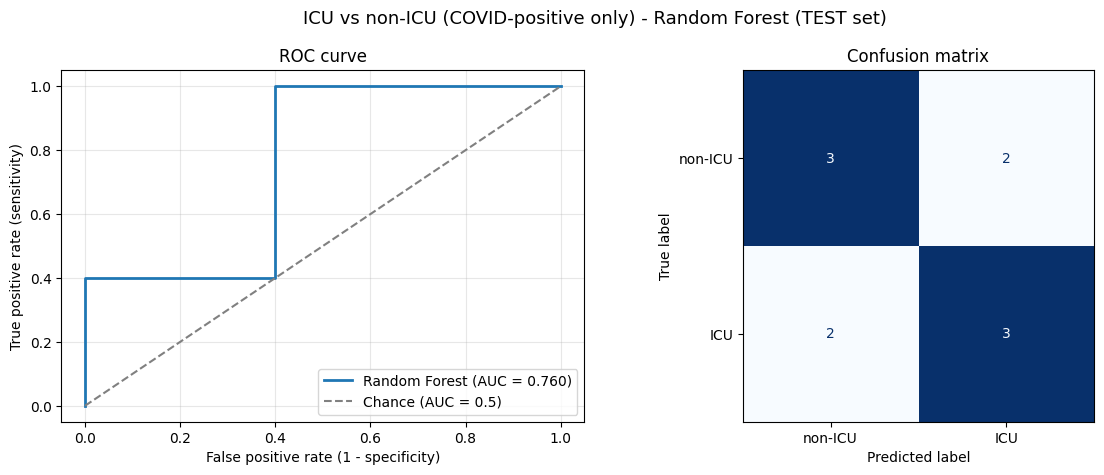

In [ ]:
m_rf_B = evaluate("Random Forest", rf_B, Tte_B, yte_B, LABELS_B, TITLE_B)

**FINAL RESULTS COMPILED**

## 10. Model comparison — ICU vs non-ICU (COVID-positive only) (test set)

In [ ]:
results_B = pd.DataFrame({"Logistic Regression (BIC genes)": m_lr_B,
                              "SVM (top 25 genes)": m_svm_B,
                              "Random Forest (top 25 genes)": m_rf_B}).T
results_B[["TN", "FP", "FN", "TP"]] = results_B[["TN", "FP", "FN", "TP"]].astype(int)
print(f"{TITLE_B} - TEST set (n = {len(yte_B)}, positive class = {LABELS_B[1]})\n")
print(results_B.round(4).to_string())

ICU vs non-ICU (COVID-positive only) - TEST set (n = 10, positive class = ICU)

                                 Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression (BIC genes)    0.9000     1.0000                0.8000       1.0000    0.8889   0.9600   5   0   1   4
SVM (top 25 genes)                 0.8000     1.0000                0.6000       1.0000    0.7500   0.0400   5   0   2   3
Random Forest (top 25 genes)       0.6000     0.6000                0.6000       0.6000    0.6000   0.7600   3   2   2   3


***FINAL EVALUATION RESULTS***

In [ ]:
summary_A = pd.DataFrame({"Logistic Regression (BIC genes)": m_lr_A,
                          "SVM (top 25 genes)":              m_svm_A,
                          "Random Forest (top 25 genes)":    m_rf_A}).T
summary_A[["TN", "FP", "FN", "TP"]] = summary_A[["TN", "FP", "FN", "TP"]].astype(int)

print(f"COVID-positive vs COVID-negative - TEST set (n = {len(yte_A)}, positive class = COVID+)\n")
print(summary_A.to_string(float_format=lambda v: f"{v:.4f}"))

COVID-positive vs COVID-negative - TEST set (n = 19, positive class = COVID+)

                                 Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression (BIC genes)    0.8947     1.0000                0.8000       1.0000    0.8889   0.9778   9   0   2   8
SVM (top 25 genes)                 0.8421     1.0000                0.7000       1.0000    0.8235   1.0000   9   0   3   7
Random Forest (top 25 genes)       0.9474     1.0000                0.9000       1.0000    0.9474   1.0000   9   0   1   9


In [ ]:
summary_B = pd.DataFrame({"Logistic Regression (BIC genes)": m_lr_B,
                          "SVM (top 25 genes)":              m_svm_B,
                          "Random Forest (top 25 genes)":    m_rf_B}).T
summary_B[["TN", "FP", "FN", "TP"]] = summary_B[["TN", "FP", "FN", "TP"]].astype(int)

print(f"ICU vs non-ICU (COVID-positive only) - TEST set (n = {len(yte_B)}, positive class = ICU)\n")
print(summary_B.to_string(float_format=lambda v: f"{v:.4f}"))

ICU vs non-ICU (COVID-positive only) - TEST set (n = 10, positive class = ICU)

                                 Accuracy  Precision  Recall (Sensitivity)  Specificity  F1 score  ROC-AUC  TN  FP  FN  TP
Logistic Regression (BIC genes)    0.9000     1.0000                0.8000       1.0000    0.8889   0.9600   5   0   1   4
SVM (top 25 genes)                 0.8000     1.0000                0.6000       1.0000    0.7500   0.0400   5   0   2   3
Random Forest (top 25 genes)       0.6000     0.6000                0.6000       0.6000    0.6000   0.7600   3   2   2   3
